In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import RandomizedSearchCV

In [4]:
data=pd.read_csv('/content/preprocessing.csv')

In [5]:
data.head()

,scholarship_received,placement_status,starting_salary_usd,gpa_or_score,test_score,origin_country_Finland,origin_country_Germany,origin_country_India,origin_country_Ireland,origin_country_Russia,...,visa_status_Schengen Student Visa,visa_status_Student Visa,visa_status_Study Permit,visa_status_Tier 4,post_graduation_visa_OPT,post_graduation_visa_PSW,post_graduation_visa_Post-Study Visa,post_graduation_visa_Work Permit,study_duration,Salary_Bin
0,0,1,0.242883,1.556464,0.679688,1,0,0,0,0,...,0,0,0,1,0,0,0,1,1.0,1
1,1,1,0.219806,-1.488781,0.765584,0,0,0,0,0,...,0,0,1,0,1,0,0,0,0.0,1
2,1,1,0.365432,-0.658260,1.023273,0,0,0,0,0,...,1,0,0,0,1,0,0,0,0.0,2
3,1,0,0.000000,-1.281151,0.336103,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0.0,1
4,1,0,0.000000,-0.589050,-1.210030,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0.5,1


In [6]:
data.shape

(4018, 172)

In [7]:
y = data["placement_status"]
X = data.drop("placement_status", axis=1)

In [8]:
X = data.drop(["starting_salary_usd", "Salary_Bin"], axis=1)
X = X.drop([col for col in X.columns if col.startswith('placement_')], axis=1)

In [9]:
correlations = pd.concat([X, y], axis=1).corr()['placement_status'].sort_values(ascending=False)
print(correlations.head(30))

placement_status                                            1.000000
field_of_study_Engineering                                  0.045214
destination_city_Vancouver                                  0.035881
destination_city_Birmingham                                 0.035158
destination_country_India                                   0.031925
university_name_Simon Fraser University                     0.027628
university_name_Higher School of Economics                  0.027493
destination_city_Pilani                                     0.026606
language_proficiency_test_IELTS                             0.025285
destination_city_Moscow                                     0.024658
destination_city_Galway                                     0.024257
destination_city_Kingston                                   0.024164
university_name_University of British Columbia              0.023073
destination_city_Mumbai                                     0.023073
destination_city_Manchester       

In [10]:
print(X.columns.tolist())

['scholarship_received', 'gpa_or_score', 'test_score', 'origin_country_Finland', 'origin_country_Germany', 'origin_country_India', 'origin_country_Ireland', 'origin_country_Russia', 'origin_country_South Africa', 'origin_country_United Arab Emirates', 'origin_country_United Kingdom', 'origin_country_United States', 'destination_country_Finland', 'destination_country_Germany', 'destination_country_India', 'destination_country_Ireland', 'destination_country_Russia', 'destination_country_South Africa', 'destination_country_United Arab Emirates', 'destination_country_United Kingdom', 'destination_country_United States', 'destination_city_Abu Dhabi', 'destination_city_Bangalore', 'destination_city_Berlin', 'destination_city_Birmingham', 'destination_city_Boston', 'destination_city_Cambridge', 'destination_city_Cape Town', 'destination_city_Chennai', 'destination_city_Chicago', 'destination_city_Cork', 'destination_city_Delhi', 'destination_city_Dubai', 'destination_city_Dublin', 'destinatio

In [11]:
from sklearn.decomposition import PCA
import pandas as pd

pca = PCA(n_components=0.95)
data_pca = pca.fit_transform(X)

print("Original shape:", X.shape)
print("Reduced shape:", data_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance retained:", pca.explained_variance_ratio_.sum())

X_pca = pd.DataFrame(data_pca, columns=[f"PC{i+1}" for i in range(data_pca.shape[1])])

y_df = pd.DataFrame(y).reset_index(drop=True)

final_df = pd.concat([X_pca, y_df], axis=1)
print(final_df.head())

Original shape: (4018, 147)
Reduced shape: (4018, 84)
Explained variance ratio: [0.1051526  0.10222717 0.02663651 0.02614604 0.02543495 0.02207555
 0.02146788 0.02127155 0.0204753  0.02028944 0.01984608 0.01820197
 0.01795211 0.01777467 0.01741657 0.01719066 0.01673716 0.01617449
 0.01563489 0.01472546 0.01443987 0.01385056 0.01334301 0.01330738
 0.01310186 0.01298656 0.0127805  0.01265761 0.01249175 0.01211105
 0.0105315  0.01042345 0.01020446 0.00983958 0.00968727 0.00951022
 0.00909573 0.00888779 0.00758314 0.00724223 0.00707334 0.00706795
 0.00696204 0.00689698 0.00685116 0.00673198 0.00670566 0.00667172
 0.00662835 0.00639113 0.00632999 0.00622101 0.00579559 0.00445425
 0.00431895 0.00413345 0.00410291 0.00394939 0.0035066  0.00347774
 0.00328067 0.00320138 0.00316807 0.0031545  0.00311636 0.00279828
 0.0026805  0.00207846 0.001964   0.00180411 0.00169256 0.0016851
 0.00167284 0.00165199 0.00163671 0.00162869 0.0016055  0.00156564
 0.00155304 0.00153769 0.00153448 0.00152942 0.001

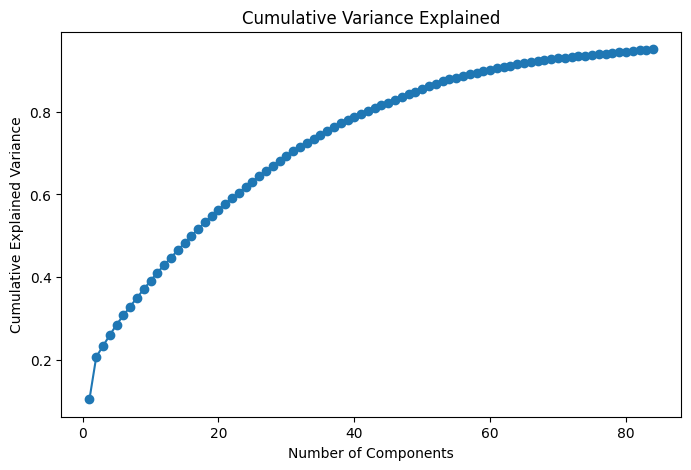

In [12]:
plt.figure(figsize=(8,5))
plt.plot(range(1, len(pca.explained_variance_ratio_)+1),
         pca.explained_variance_ratio_.cumsum(), marker='o')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Variance Explained")
plt.show()

In [13]:
X_model = X.copy()
y_model =y.copy()

In [14]:
X_train, X_test, y_train, y_test = train_test_split( X_model, y_model, test_size=0.2, stratify=y_model, random_state=42)

In [15]:
gb_model = GradientBoostingClassifier()
gb_model.fit(X_train, y_train)

GradientBoostingClassifier()

In [ ]:
param_grid_gb = {
    'n_estimators': [100, 200],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5],
    'subsample': [0.8, 1.0]
}

grid_gb = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid_gb,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_gb.fit(X_train, y_train)

print("Best Parameters (Gradient Boosting):", grid_gb.best_params_)
print("Best Cross-Validation Accuracy:", grid_gb.best_score_)

y_pred_gb = grid_gb.best_estimator_.predict(X_test)
print("Test Accuracy:", accuracy_score(y_test, y_pred_gb))

In [ ]:
param_dist_gb = {
    'n_estimators': [100, 150, 200, 250],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 4, 5, 6],
    'subsample': [0.8, 0.9, 1.0]
}

rand_gb = RandomizedSearchCV(
    estimator=gb_model,
    param_distributions=param_dist_gb,
    n_iter=10,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

rand_gb.fit(X_train, y_train)

print("Best Parameters (Gradient Boosting):", rand_gb.best_params_)
print("Best CV Accuracy:", rand_gb.best_score_)

y_pred_gb = rand_gb.best_estimator_.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred_gb))

In [ ]:
print("Gradient Boosting Evaluation Comparison")
print("="*60)

best_gb_grid = grid_gb.best_estimator_
y_pred_gb_grid = best_gb_grid.predict(X_test)
y_prob_gb_grid = best_gb_grid.predict_proba(X_test)[:, 1]

print("\nGridSearchCV Results:")
print("Best Parameters:", grid_gb.best_params_)
print("CV Accuracy    :", grid_gb.best_score_)
print("Test Accuracy  :", accuracy_score(y_test, y_pred_gb_grid))
print("Precision      :", precision_score(y_test, y_pred_gb_grid))
print("Recall         :", recall_score(y_test, y_pred_gb_grid))
print("F1 Score       :", f1_score(y_test, y_pred_gb_grid))
print("AUC Score      :", roc_auc_score(y_test, y_prob_gb_grid))

best_gb_random = rand_gb.best_estimator_
y_pred_gb_random = best_gb_random.predict(X_test)
y_prob_gb_random = best_gb_random.predict_proba(X_test)[:, 1]

print("\nRandomizedSearchCV Results:")
print("Best Parameters:", rand_gb.best_params_)
print("CV Accuracy    :", rand_gb.best_score_)
print("Test Accuracy  :", accuracy_score(y_test, y_pred_gb_random))
print("Precision      :", precision_score(y_test, y_pred_gb_random))
print("Recall         :", recall_score(y_test, y_pred_gb_random))
print("F1 Score       :", f1_score(y_test, y_pred_gb_random))
print("AUC Score      :", roc_auc_score(y_test, y_prob_gb_random))


In [ ]:
cm_grid = confusion_matrix(y_test, y_pred_gb_grid)
disp_grid = ConfusionMatrixDisplay(confusion_matrix=cm_grid, display_labels=['Not Placed', 'Placed'])
disp_grid.plot()
plt.title('Confusion Matrix (GridSearchCV)')
plt.show()

cm_random = confusion_matrix(y_test, y_pred_gb_random)
disp_random = ConfusionMatrixDisplay(confusion_matrix=cm_random, display_labels=['Not Placed', 'Placed'])
disp_random.plot()
plt.title('Confusion Matrix (RandomizedSearchCV)')
plt.show()